# 2.2 Entrenamiento y ajuste de hiperparámetros

Entrenamiento de YOLOv11n y YOLOv11s sobre `Data_final` (1280 px) con el diseño de `docs/plan_oe2.md`, en tres fases. Cada fase se ejecuta en una sesión de Google Colab (A100) y descarga sus resultados al terminar.

| Fase | Qué entrena | Corridas | Depende de |
| :--- | :--- | :---: | :--- |
| **1. Cribado** | Por modelo, en `train` / `valid` y con 3 semillas por configuración: la referencia, los optimizadores, la tasa de aprendizaje y el aumento, en ese orden | 48 | — |
| **2. Confirmación** | La configuración ganadora del cribado frente a la referencia, en los 4 pliegues de la validación cruzada del OE1 y con 2 semillas, con corridas propias | 0 a 16 por modelo | Cribado |
| **3. Final** | La configuración adoptada, con 3 semillas y hasta 200 épocas | 6 | Confirmación |

**Reglas de decisión, fijadas antes de entrenar:**
- **Cribado:** cada configuración se entrena con 3 semillas (13, 29 y 51) y se compara por su mAP50-95 medio. En cada paso se adopta la mejor alternativa solo si supera a la configuración base en al menos **+0.005**; si no, se mantiene la base. Promediar 3 semillas reduce el ruido de la comparación, lo que permite exigir una mejora menor que con una sola semilla. El cribado se ejecutó primero con 2 semillas y se amplió a 3, añadiendo la semilla 51 a todas las configuraciones por igual.
- **Confirmación:** la ganadora se compara con la referencia en los 4 pliegues y con las semillas 13 y 29: 8 comparaciones emparejadas por pliegue y semilla. Se adopta solo si mejora a la referencia en al menos +0.005 de media de forma significativa (t pareada, p < 0.05). La confirmación se ejecutó primero con la semilla 13 (4 comparaciones) y se amplió con la semilla 29 para aumentar la potencia de la prueba, sin cambiar la regla. Si la ganadora del cribado es la propia referencia, no hace falta confirmar.
- **Final:** el umbral de confianza para el conteo es el que maximiza el F1 en `valid`.

**Tamaño de lote:** no se ajusta. Se usa el valor por defecto de Ultralytics, 16, en la confirmación y en el entrenamiento final; el cribado se ejecutó con lote 8, el del protocolo del OE1.

**Protocolo común:** 1280 px, transferencia desde COCO con todas las capas afinadas, 100 épocas en el ajuste, semilla fija y modo determinista. Con Adam y AdamW, `warmup_bias_lr = 0`, como hace Ultralytics en su modo `'auto'`. Cada corrida conserva su carpeta de Ultralytics, con `best.pt` como único peso, y una fila en el registro de corridas (`resultados/experimentos/<fase>.csv`, un archivo por fase). El test no se usa.

In [1]:
FASE = 'cribado'                       # 'cribado', 'confirmacion' o 'final'
MODELOS_SESION = ('yolo11n', 'yolo11s')   # opcional: un solo modelo por sesión para acortarla

In [2]:
# --- Entorno: local (análisis) o Colab (entrenamiento) ---
import os, sys, glob, shutil, subprocess, zipfile
from pathlib import Path

PLATAFORMA = 'colab' if 'COLAB_RELEASE_TAG' in os.environ else 'kaggle' if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ else 'local'
if PLATAFORMA == 'local':
    RAIZ = Path.cwd()
else:
    os.environ['YOLO_VERBOSE'] = 'False'   # sin barras de progreso de Ultralytics: con tantas corridas, la página de Colab se congela
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.174', 'albumentations==2.0.8'], check=True)
    base = Path('/kaggle/working') if PLATAFORMA == 'kaggle' else Path('/content')
    RAIZ = base / 'maiz-yolo11' / 'oe2'
    if not (RAIZ / 'comun_oe2.py').exists():
        if PLATAFORMA == 'colab':   # el paquete está en Google Drive, que solo se lee
            from google.colab import drive
            drive.mount('/content/drive')
        origen = '/kaggle/input' if PLATAFORMA == 'kaggle' else '/content/drive/MyDrive'
        paquete = glob.glob(f'{origen}/oe2_nube*.zip') or glob.glob(f'{origen}/**/oe2_nube*.zip', recursive=True)
        assert paquete, 'No se encontró oe2_nube.zip'
        zipfile.ZipFile(paquete[0]).extractall(base)
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
import comun_oe2 as E

C = E.C
if isinstance(MODELOS_SESION, str):   # ('yolo11s') sin coma es un texto, no una tupla
    MODELOS_SESION = (MODELOS_SESION,)
assert set(MODELOS_SESION) <= set(E.MODELOS), f'MODELOS_SESION debe contener {E.MODELOS}'
C.estilo()
REGISTRO, RUNS, TRABAJO = E.REGISTRO, E.RUNS, E.TRABAJO   # oe2/resultados/experimentos/<fase>.csv, runs/oe2/, trabajo/oe2/
SALIDA = RAIZ / 'salida' / '2.2_entrenamiento'
if PLATAFORMA != 'local':
    # Descargas de una sesión anterior interrumpida, subidas a /content: se reanuda desde ahí
    for previo in glob.glob(str(base / 'oe2_*.zip')):
        E.integrar_descarga(previo)
    assert torch.cuda.is_available(), 'No hay GPU: Entorno de ejecución > Cambiar tipo de entorno > A100'
    E.registrar_entorno(RAIZ / 'resultados')
    if 'A100' not in torch.cuda.get_device_name(0):
        print('AVISO: la GPU no es una A100; las corridas del OE2 deben hacerse todas en la misma GPU.')
print(f'Plataforma: {PLATAFORMA} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna"} | '
      f'fase: {FASE} | corridas en el registro: {len(E.leer_registro(REGISTRO))}')

Plataforma: local | GPU: NVIDIA GeForce RTX 3060 Laptop GPU | fase: cribado | corridas en el registro: 76


## 1. Corridas de la fase

Solo se ejecuta en la nube. Las corridas ya registradas se omiten, así que la fase puede reanudarse.

In [3]:
import time

def entrenar(modelo, cfg, semilla, particion):
    print(f'-> {E.id_corrida(modelo, cfg, semilla, particion)}', flush=True)
    f = E.entrenar(modelo, cfg, semilla, particion, FASE, RUNS, REGISTRO, TRABAJO)
    print(f"   mAP50-95 {f['mAP50_95']:.4f} | mejor época {f['mejor_epoca']} de {f['epocas_ejecutadas']} | "
          f"{f['minutos']} min | VRAM {f['vram_gb']} GB", flush=True)
    return f

if PLATAFORMA != 'local':
    t0, antes = time.time(), len(E.leer_registro(REGISTRO))
    try:
        for modelo in MODELOS_SESION:
            if FASE == 'cribado':
                E.cribado(modelo, REGISTRO, entrenar)
                continue
            _, ganadora = E.cribado(modelo, REGISTRO)
            assert ganadora is not None, f'{modelo}: el cribado no está completo en el registro (subir la descarga de la fase anterior a /content)'
            if FASE == 'confirmacion':
                E.confirmacion(modelo, ganadora, REGISTRO, entrenar)
                continue
            _, adoptada = E.confirmacion(modelo, ganadora, REGISTRO)
            assert adoptada is not None, f'{modelo}: la confirmación no está completa en el registro (subir la descarga de la fase anterior a /content)'
            for semilla in E.SEMILLAS_FINAL:
                E.obtener_map(REGISTRO, modelo, adoptada, semilla, 'final', entrenar)
    except Exception:   # una corrida fallida no impide descargar las ya completadas
        import traceback; traceback.print_exc()
        print('La fase se interrumpió: se descargan las corridas completadas; al volver a ejecutar, se reanuda.')
    print(f'{len(E.leer_registro(REGISTRO)) - antes} corridas nuevas en {(time.time() - t0) / 3600:.1f} h')

In [4]:
# Descarga de la fase: el CSV de la fase, el entorno y las carpetas de sus corridas (best.pt, curvas, argumentos),
# con las rutas del repositorio. En local se incorpora con E.integrar_descarga.
if PLATAFORMA != 'local':
    reg = E.leer_registro(REGISTRO)
    sufijo = '' if set(MODELOS_SESION) == set(E.MODELOS) else '_' + '_'.join(MODELOS_SESION)
    destino = base / f'oe2_{FASE}{sufijo}.zip'
    with zipfile.ZipFile(destino, 'w', zipfile.ZIP_DEFLATED) as z:
        for f in [REGISTRO / f'{FASE}.csv', *(RAIZ / 'resultados').glob('entorno_*.json')]:
            z.write(f, f.relative_to(E.REPO))
        for rid in reg.loc[(reg['fase'] == FASE) & reg['modelo'].isin(MODELOS_SESION), 'id']:
            for f in (RUNS / rid).rglob('*'):
                if f.is_file():   # los .pt ya están comprimidos
                    z.write(f, f.relative_to(E.REPO), compress_type=zipfile.ZIP_STORED if f.suffix == '.pt' else zipfile.ZIP_DEFLATED)
    print(f'{destino} ({destino.stat().st_size / 1e6:.0f} MB)')
    if PLATAFORMA == 'colab':
        from google.colab import files
        files.download(str(destino))

## 2. Análisis

Se ejecuta en local, después de incorporar la descarga de cada fase con `E.integrar_descarga('oe2_<fase>.zip')`.

### 2.1. Cribado

Para cada modelo, el mAP50-95 medio en `valid` de cada configuración (3 semillas) y su desviación estándar. Verde: la referencia y cada alternativa adoptada; un paso sin verde mantuvo la configuración anterior. La línea continua marca la referencia, y la discontinua, la referencia + 0.005.

yolo11n: ganadora del cribado = {'optimizer': 'SGD', 'lr0': 0.01, 'batch': 8, 'aumento': 'A'}


,paso,optimizer,lr0,batch,aumento,mAP50_95,sd,semilla 13,semilla 29,semilla 51,elegida
0,Referencia,SGD,0.010,8,A,0.7146,0.0037,0.7186,0.7140,0.7113,True
1,Optimizador,MuSGD,0.010,8,A,0.7111,0.0070,0.7052,0.7188,0.7093,False
2,Optimizador,Adam,0.001,8,A,0.7094,0.0017,0.7106,0.7074,0.7102,False
3,Optimizador,AdamW,0.001,8,A,0.7031,0.0004,0.7026,0.7032,0.7034,False
4,Tasa de aprendizaje,SGD,0.005,8,A,0.7068,0.0029,0.7044,0.7100,0.7060,False
5,Tasa de aprendizaje,SGD,0.020,8,A,0.7152,0.0048,0.7099,0.7163,0.7193,False
6,Aumento,SGD,0.010,8,B,0.7082,0.0020,0.7099,0.7089,0.7060,False
7,Aumento,SGD,0.010,8,C,0.7109,0.0074,0.7045,0.7093,0.7190,False


yolo11s: ganadora del cribado = {'optimizer': 'SGD', 'lr0': 0.01, 'batch': 8, 'aumento': 'C'}


,paso,optimizer,lr0,batch,aumento,mAP50_95,sd,semilla 13,semilla 29,semilla 51,elegida
0,Referencia,SGD,0.010,8,A,0.7241,0.0020,0.7219,0.7259,0.7244,True
1,Optimizador,MuSGD,0.010,8,A,0.7201,0.0057,0.7233,0.7234,0.7136,False
2,Optimizador,Adam,0.001,8,A,0.7193,0.0048,0.7237,0.7199,0.7142,False
3,Optimizador,AdamW,0.001,8,A,0.7159,0.0055,0.7095,0.7186,0.7195,False
4,Tasa de aprendizaje,SGD,0.005,8,A,0.7286,0.0072,0.7270,0.7224,0.7364,False
5,Tasa de aprendizaje,SGD,0.020,8,A,0.7157,0.0029,0.7130,0.7187,0.7154,False
6,Aumento,SGD,0.010,8,B,0.7246,0.0040,0.7269,0.7268,0.7199,False
7,Aumento,SGD,0.010,8,C,0.7310,0.0065,0.7381,0.7296,0.7252,True


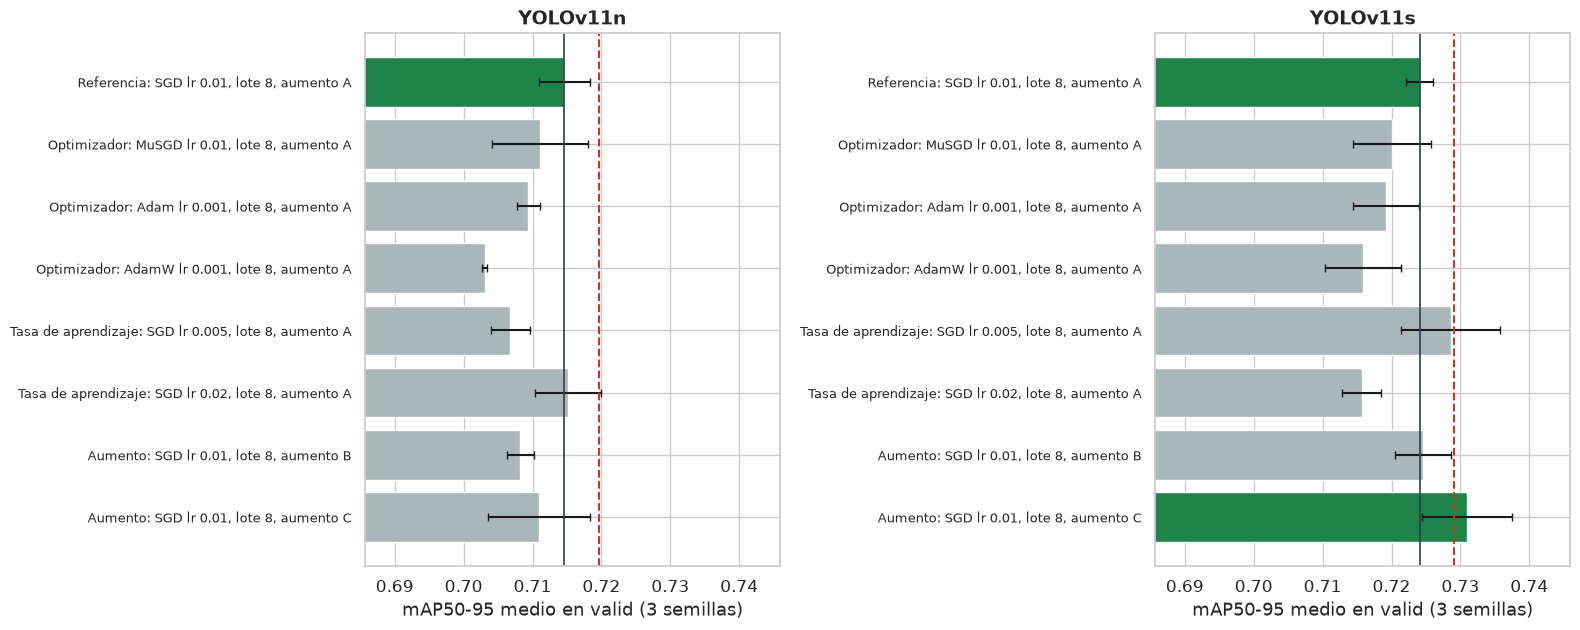

In [5]:
cribados = {}
for modelo in E.MODELOS:
    tabla, ganadora = E.cribado(modelo, REGISTRO)
    cribados[modelo] = (tabla, ganadora)
    print(f'{modelo}: ganadora del cribado = {ganadora if ganadora else "cribado incompleto"}')
    display(tabla.round(4))

if all(g is not None for _, g in cribados.values()):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True)
    for ax, (modelo, (tabla, _)) in zip(axes, cribados.items()):
        etiquetas = [f"{p}: {o} lr {lr:g}, lote {b}, aumento {a}"
                     for p, o, lr, b, a in tabla[['paso', 'optimizer', 'lr0', 'batch', 'aumento']].itertuples(index=False)]
        y = np.arange(len(tabla))[::-1]
        ax.barh(y, tabla['mAP50_95'], xerr=tabla['sd'], capsize=3, color=[E.OK if e else '#AAB7B8' for e in tabla['elegida']])
        ref = tabla['mAP50_95'].iloc[0]
        ax.axvline(ref, color=E.NEUTRO, lw=1.2); ax.axvline(ref + E.GANANCIA_MIN, color=E.MAL, ls='--', lw=1.5)
        ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=9); ax.set_title(modelo.replace('yolo11', 'YOLOv11'))
        ax.set_xlim(tabla['mAP50_95'].min() - 0.03, tabla['mAP50_95'].max() + 0.015); ax.set_xlabel(f'mAP50-95 medio en valid ({len(E.SEMILLAS_CRIBADO)} semillas)')
    C.guardar(SALIDA, 'cribado.png')

### 2.2. Confirmación

mAP50-95 de la referencia y de la ganadora del cribado en cada pliegue y semilla, con la diferencia media, en cuántas de las 8 comparaciones gana la candidata y el valor p.

In [6]:
adoptadas = {}
for modelo, (_, ganadora) in cribados.items():
    if ganadora is None:
        print(f'{modelo}: cribado incompleto'); continue
    tabla, adoptada = E.confirmacion(modelo, ganadora, REGISTRO)
    adoptadas[modelo] = adoptada
    if ganadora == E.REFERENCIA:
        print(f'{modelo}: la ganadora del cribado es la referencia; no hace falta confirmar')
        continue
    print(f"{modelo}: diferencia media {tabla.attrs.get('diferencia', float('nan')):+.4f}, a favor de la candidata en "
          f"{tabla.attrs.get('a_favor', '?')} de {len(tabla)}, valor p {tabla.attrs.get('valor_p', float('nan')):.3f} "
          f"-> adoptada: {adoptada if adoptada else 'confirmación incompleta'}")
    display(tabla.assign(diferencia=tabla['candidata'] - tabla['referencia']).round(4))

yolo11n: la ganadora del cribado es la referencia; no hace falta confirmar
yolo11s: diferencia media +0.0123, a favor de la candidata en 6 de 8, valor p 0.182 -> adoptada: {'optimizer': 'SGD', 'lr0': 0.01, 'batch': 16, 'aumento': 'A'}


referencia  candidata  diferencia
pliegue semilla                                   
0       13           0.7602     0.7737      0.0135
        29           0.7677     0.7703      0.0025
1       13           0.7249     0.7749      0.0500
        29           0.7362     0.7835      0.0473
2       13           0.7294     0.7226     -0.0068
        29           0.7120     0.7147      0.0027
3       13           0.7729     0.7618     -0.0111
        29           0.7622     0.7629      0.0007

### 2.3. Entrenamiento final

Media y desviación de las 3 semillas por modelo, acierto por subtipo y curvas de validación por época (el punto marca la época de `best.pt`). Las métricas de aplicación (MAE de conteo y acierto por subtipo) se calculan al umbral de máximo F1 de cada corrida; el umbral de conteo de cada modelo es la mediana de esos umbrales.

modelo                   yolo11n   yolo11s
mAP50_95          mean    0.7128    0.7207
                  std     0.0037    0.0055
mAP50             mean    0.9603    0.9580
                  std     0.0074    0.0051
mAP75             mean    0.8437    0.8556
                  std     0.0170    0.0080
precision         mean    0.8629    0.8853
                  std     0.0222    0.0082
recall            mean    0.9210    0.9103
                  std     0.0090    0.0115
AP50_95_Healthy   mean    0.7047    0.7321
                  std     0.0026    0.0142
AP50_95_Defect    mean    0.7209    0.7092
                  std     0.0073    0.0250
f1_max            mean    0.8875    0.8955
                  std     0.0100    0.0079
conf_f1           mean    0.3984    0.4535
                  std     0.0416    0.0174
mae_conteo        mean    0.4762    0.3980
                  std     0.0212    0.1380
mejor_epoca       mean   71.3333   80.0000
                  std    23.0290   33.7787
epocas_ejecutadas mean  121.3333  130.0000
                  std    23.0290   33.7787
minutos           mean    8.4000   10.8667
                  std     1.5524    2.7683
vram_gb           mean   18.5767   24.5267
                  std     1.0477    0.2026

,Broken,Damage,Fungus,Healthy,Immature,Shriveled,Weeveled
modelo,,,,,,,
yolo11n,0.927,0.931,0.980,0.840,0.753,0.968,0.892
yolo11s,0.843,0.847,0.967,0.897,0.838,0.918,0.867


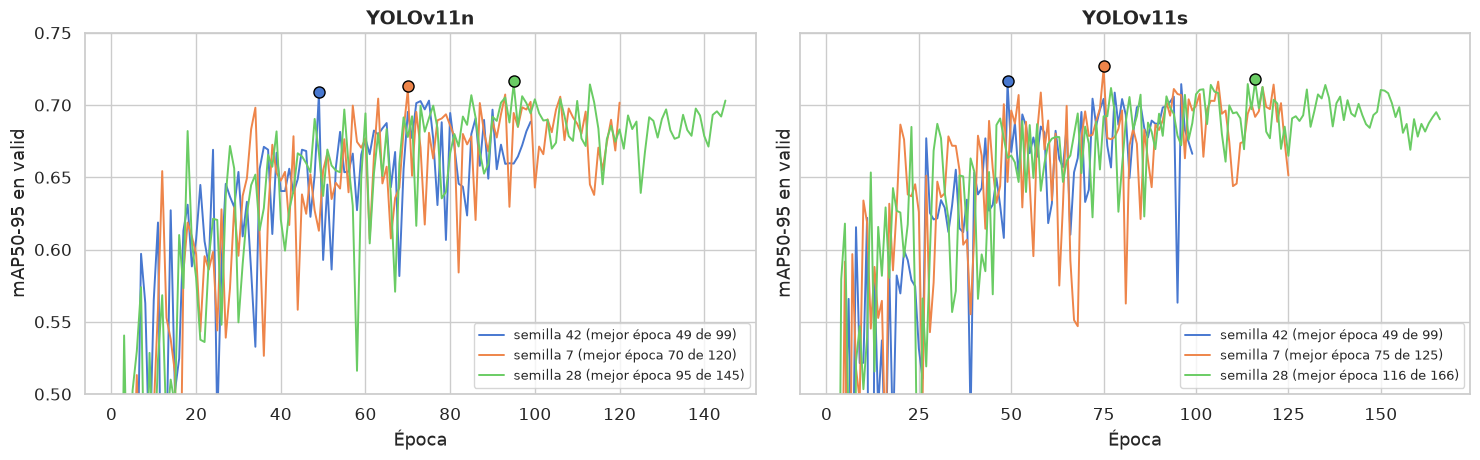

{
 "yolo11n": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "conf_conteo": 0.397,
  "pesos": [
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s42_final/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s7_final/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s28_final/weights/best.pt"
  ]
 },
 "yolo11s": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "conf_conteo": 0.457,
  "pesos": [
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s42_final/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s7_final/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s28_final/weights/best.pt"
  ]
 }
}


In [7]:
reg = E.leer_registro(REGISTRO)
fin = reg[reg['particion'] == 'final'] if 'particion' in reg else reg.iloc[0:0]
if len(fin) < len(E.MODELOS) * len(E.SEMILLAS_FINAL):
    print(f'Entrenamiento final incompleto: {len(fin)} de {len(E.MODELOS) * len(E.SEMILLAS_FINAL)} corridas')
else:
    metr = ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'AP50_95_Healthy', 'AP50_95_Defect', 'f1_max', 'conf_f1',
            'mae_conteo', 'mejor_epoca', 'epocas_ejecutadas', 'minutos', 'vram_gb']
    display(fin.groupby('modelo')[metr].agg(['mean', 'std']).round(4).T)
    # Acierto por subtipo (clase binaria correcta, IoU >= 0.5) al umbral de máximo F1: media de las 3 semillas
    display(fin.groupby('modelo')[[c for c in fin.columns if c.startswith('acierto_')]].mean()
            .rename(columns=lambda c: c.removeprefix('acierto_')).round(3))
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    for ax, modelo in zip(axes, E.MODELOS):
        for _, f in fin[fin['modelo'] == modelo].iterrows():
            curva = pd.read_csv(RUNS / f['id'] / 'results.csv'); curva.columns = [c.strip() for c in curva.columns]
            linea, = ax.plot(curva['epoch'], curva['metrics/mAP50-95(B)'], lw=1.4,
                             label=f"semilla {int(f['semilla'])} (mejor época {int(f['mejor_epoca'])} de {int(f['epocas_ejecutadas'])})")
            ax.plot(f['mejor_epoca'], f['mAP50_95'], 'o', ms=8, color=linea.get_color(), mec='black')
        ax.set_ylim(0.5, 0.75)   # las primeras épocas, por debajo de 0.5, no aportan a la lectura de la convergencia
        ax.set_title(modelo.replace('yolo11', 'YOLOv11')); ax.set_xlabel('Época'); ax.set_ylabel('mAP50-95 en valid'); ax.legend(fontsize=9)
    C.guardar(SALIDA, 'convergencia_final.png')
    config = {m: {**adoptadas[m], 'conf_conteo': round(float(fin[fin['modelo'] == m]['conf_f1'].median()), 3),
                  'pesos': [str((RUNS / i / 'weights' / 'best.pt').relative_to(E.REPO)) for i in fin[fin['modelo'] == m]['id']]} for m in E.MODELOS}
    (RAIZ / 'resultados' / 'configuracion_final.json').write_text(json.dumps(config, indent=1, ensure_ascii=False))
    print(json.dumps(config, indent=1, ensure_ascii=False))

## 3. Paquete para la nube

Se genera en local: `nube/oe2_nube.zip`, con `Data_final`, la partición del OE1 y el código. Se copia a Google Drive, que solo se lee.

In [8]:
if PLATAFORMA == 'local':
    archivos = [C.RAIZ / 'comun.py', C.RAIZ / 'resultados' / 'particion.json', RAIZ / 'comun_oe2.py', RAIZ / '2.2_entrenamiento.ipynb']
    archivos += sorted(REGISTRO.glob('*.csv'))   # fases ya hechas: la nube las lee y omite sus corridas
    archivos += sorted(p for p in E.FINAL.rglob('*') if p.is_file() and p.suffix != '.cache')
    destino = C.NUBE / 'oe2_nube.zip'
    destino.parent.mkdir(exist_ok=True)
    with zipfile.ZipFile(destino, 'w') as z:
        for p in archivos:
            z.write(p, Path(E.REPO.name) / p.relative_to(E.REPO), compress_type=zipfile.ZIP_STORED if p.suffix == '.jpg' else zipfile.ZIP_DEFLATED)
    print(f'{destino} ({destino.stat().st_size / 1e6:.0f} MB, {len(archivos)} archivos)')

/home/ismael/Documents/Tesis/maiz-yolo11/nube/oe2_nube.zip (154 MB, 1548 archivos)
